# Modellierung

## Init

In [137]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path, index_col=0)

# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Model 1

## Datenselektierung

In [138]:
# Prepare features and target
X = df[['n_duty', 'n_sby', 'month', 'season', 'day_of_week', 'is_holiday', 'is_weekend', 'n_sick']] 

y = df['calls']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Modellierungvergleiche

In [3]:

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Support Vector Machine': SVR(),
    'K-Nearest Neighbors': KNeighborsRegressor(),
    'Neural Network': MLPRegressor(random_state=42, max_iter=1000),
    'Lasso Regression': Lasso(random_state=42),
    'Ridge Regression': Ridge(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

# Train and evaluate each model
results = {}
for model_name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time() 

    training_time = end_time - start_time
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results[model_name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, "Training Time" : training_time}
    print(f'{model_name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}, "Training Time (s)" : {training_time}')


Linear Regression - MAE: 844.4126492385662, MSE: 1093068.6499148447, RMSE: 1045.4992347748728, R2: 0.2917026183891873, "Training Time (s)" : 0.0025196075439453125
Decision Tree - MAE: 1061.2857142857142, MSE: 1785570.4285714286, RMSE: 1336.252382063893, R2: -0.15703149965683005, "Training Time (s)" : 0.003475666046142578
Random Forest - MAE: 821.3105553494125, MSE: 1057683.3492077144, RMSE: 1028.4373336318138, R2: 0.31463193379890486, "Training Time (s)" : 0.20725321769714355
Gradient Boosting - MAE: 772.6675382558404, MSE: 902563.3257017874, RMSE: 950.0333287320963, R2: 0.4151481333013015, "Training Time (s)" : 0.060617685317993164
Support Vector Machine - MAE: 1010.6427763456301, MSE: 1580034.105334653, RMSE: 1256.9940752981508, R2: -0.023846050064196378, "Training Time (s)" : 0.027977705001831055
K-Nearest Neighbors - MAE: 821.916883116883, MSE: 1076238.8509090908, RMSE: 1037.4193226025293, R2: 0.30260815718562095, "Training Time (s)" : 0.0016083717346191406
Neural Network - MAE: 88

/usr/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Models sorted by MAE:


,MAE,MSE,RMSE,R2,Training Time
Gradient Boosting,772.667538,9.025633e+05,950.033329,0.415148,0.060618
Random Forest,821.310555,1.057683e+06,1028.437334,0.314632,0.207253
K-Nearest Neighbors,821.916883,1.076239e+06,1037.419323,0.302608,0.001608
Lasso Regression,844.352199,1.092898e+06,1045.417683,0.291813,0.001745
Ridge Regression,844.391879,1.093036e+06,1045.483792,0.291724,0.001223
Linear Regression,844.412649,1.093069e+06,1045.499235,0.291703,0.002520
Neural Network,886.860897,1.212784e+06,1101.264782,0.214128,2.198641
XGBoost,912.439350,1.291794e+06,1136.571225,0.162931,0.037225
Support Vector Machine,1010.642776,1.580034e+06,1256.994075,-0.023846,0.027978
Decision Tree,1061.285714,1.785570e+06,1336.252382,-0.157031,0.003476


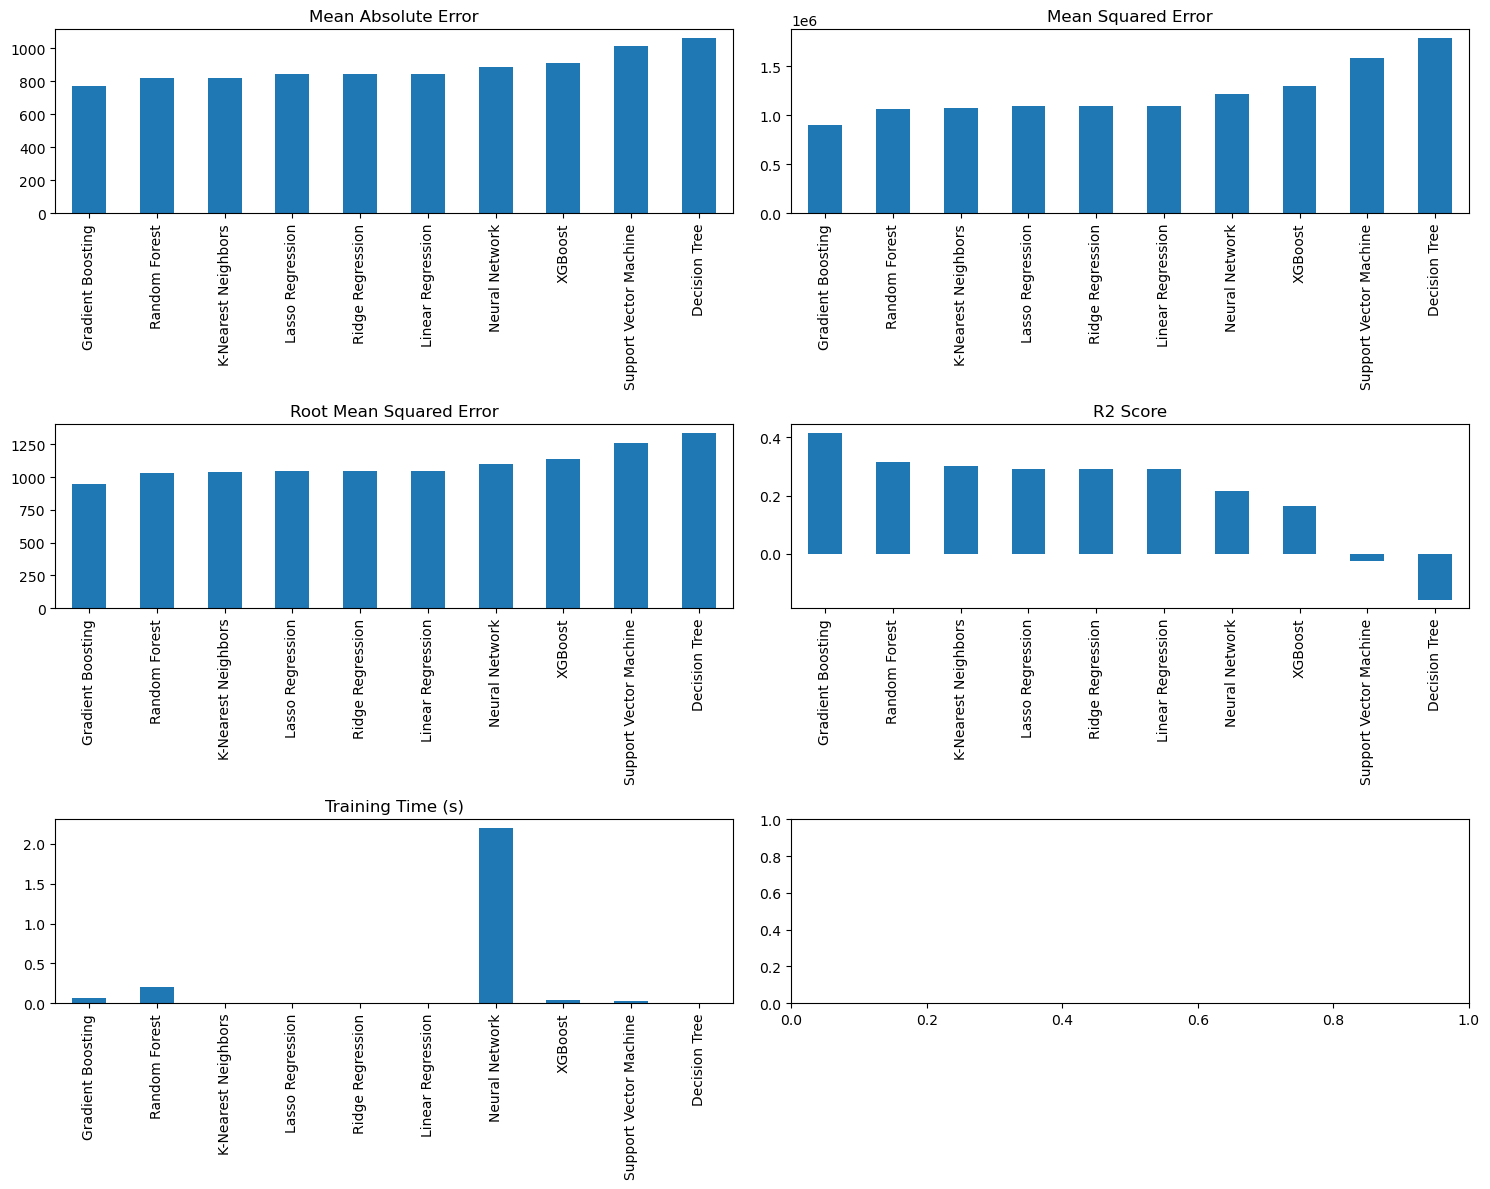

In [6]:
# Convert results to a DataFrame for easier comparison
results_df = pd.DataFrame(results).T

# Sort the models by MAE (you can change the metric to sort by other scores)
results_df_sorted = results_df.sort_values(by='MAE')

print("Models sorted by MAE:")
display(results_df_sorted)

# Visualize the results
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
results_df_sorted['MAE'].plot(kind='bar', ax=axes[0, 0], title='Mean Absolute Error')
results_df_sorted['MSE'].plot(kind='bar', ax=axes[0, 1], title='Mean Squared Error')
results_df_sorted['RMSE'].plot(kind='bar', ax=axes[1, 0], title='Root Mean Squared Error')
results_df_sorted['R2'].plot(kind='bar', ax=axes[1, 1], title='R2 Score')
results_df_sorted['Training Time'].plot(kind='bar', ax=axes[2, 0], title='Training Time (s)')
plt.tight_layout()
plt.show()

In [7]:
# Select the best model based on MAE
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Best Model: Gradient Boosting
MAE                 772.667538
MSE              902563.325702
RMSE                950.033329
R2                    0.415148
Training Time         0.060618
Name: Gradient Boosting, dtype: float64


Final Evaluation of the Best Model (Gradient Boosting):
MAE: 772.6675382558404, MSE: 902563.3257017874, RMSE: 950.0333287320963, R2: 0.4151481333013015


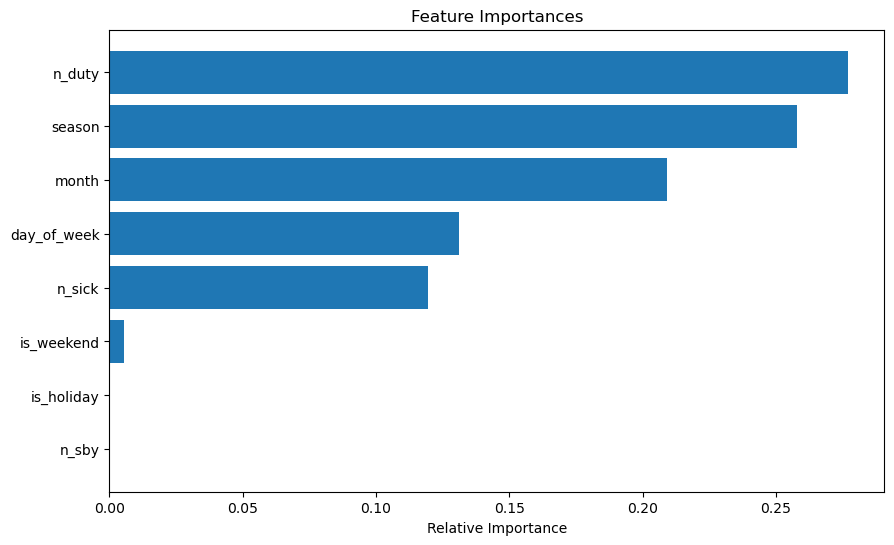

In [8]:
# If further fine-tuning is needed, you can perform hyperparameter tuning on the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
# Add similar tuning for other models if needed

# Train the best model with the entire dataset
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Final evaluation of the best model
final_mae = mean_absolute_error(y_test, y_pred_best)
final_mse = mean_squared_error(y_test, y_pred_best)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_best)

print(f'Final Evaluation of the Best Model ({best_model_name}):')
print(f'MAE: {final_mae}, MSE: {final_mse}, RMSE: {final_rmse}, R2: {final_r2}')


# Feature Importance for the best model
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()


## Modell mit weniger Features (nur die wichtigsten)

In [9]:
best_model_1 = grid_search.best_estimator_

best_model_1.fit(X_train, y_train)

X = df[['n_duty', 'season', 'month', 'day_of_week']]
y = df['calls']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

best_model_1.fit(X_train, y_train)

GradientBoostingRegressor(random_state=42)

## Prediction Test

In [10]:
predict_data = pd.DataFrame([{
        'n_duty' : 5000, 
        'season' : 1,
        'month' : 5,
        'day_of_week' : 4
    }])


best_model_1.predict(predict_data)

array([9054.15804644])

## Export model

In [11]:
import joblib

# Modell speichern
joblib.dump(best_model_1, '../../app/models/calls_model.pkl')

['../../app/models/calls_model.pkl']

# Full test

In [94]:
import joblib

model_1 = joblib.load('../../app/models/calls_model.pkl')

In [117]:
# Prepare features and target
X = df[['n_duty', 'n_sby', 'month', 'season', 'day_of_week', 'is_holiday', 'is_weekend', "calls", "n_sick"]] 

X = X.rename(columns={"calls" : "orig_calls"})

y = df[['sby_need']]

# Split data into training and test sets
_, X_test, _, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [118]:
X_test

,n_duty,n_sby,month,season,day_of_week,is_holiday,is_weekend,orig_calls,n_sick
174,1700,90,9,3,3,False,False,8286.0,77
754,1900,90,4,1,2,False,False,9174.0,55
584,1800,90,11,3,0,False,False,7494.0,64
240,1700,90,11,3,6,False,True,5526.0,65
715,1900,90,3,1,5,False,True,7932.0,72
...,...,...,...,...,...,...,...,...,...
359,1800,90,3,1,6,False,True,6756.0,48
63,1700,90,6,2,4,False,False,8922.0,69
388,1800,90,4,1,0,False,False,8184.0,68
1068,1900,90,3,1,1,False,False,9312.0,62


In [119]:
y_test

,sby_need
174,35.0
754,0.0
584,0.0
240,0.0
715,0.0
...,...
359,0.0
63,154.0
388,0.0
1068,25.0


In [120]:
X_test["calls"] = model_1.predict(X_test[['n_duty', 'season', 'month', 'day_of_week']])

In [121]:
X_test

,n_duty,n_sby,month,season,day_of_week,is_holiday,is_weekend,orig_calls,n_sick,calls
174,1700,90,9,3,3,False,False,8286.0,77,7809.778381
754,1900,90,4,1,2,False,False,9174.0,55,9460.754232
584,1800,90,11,3,0,False,False,7494.0,64,7692.080373
240,1700,90,11,3,6,False,True,5526.0,65,6035.428267
715,1900,90,3,1,5,False,True,7932.0,72,8651.636445
...,...,...,...,...,...,...,...,...,...,...
359,1800,90,3,1,6,False,True,6756.0,48,6587.451032
63,1700,90,6,2,4,False,False,8922.0,69,7828.840258
388,1800,90,4,1,0,False,False,8184.0,68,8597.652857
1068,1900,90,3,1,1,False,False,9312.0,62,8812.034985


In [131]:
X_test["sby_need_based_on_orig_calls"] = X_test.apply(lambda row: max(0, (row.orig_calls / 5) - row.n_duty + row.n_sby) , axis=1)

In [132]:
X_test["sby_need_based_on_calls"] = X_test.apply(lambda row: max(0, (row.calls / 5) - row.n_duty + row.n_sby ), axis=1)

In [133]:
X_test

,n_duty,n_sby,month,season,day_of_week,is_holiday,is_weekend,orig_calls,n_sick,calls,sby_need_based_on_orig_calls,sby_need_based_on_calls
174,1700,90,9,3,3,False,False,8286.0,77,7809.778381,47.2,0.000000
754,1900,90,4,1,2,False,False,9174.0,55,9460.754232,24.8,82.150846
584,1800,90,11,3,0,False,False,7494.0,64,7692.080373,0.0,0.000000
240,1700,90,11,3,6,False,True,5526.0,65,6035.428267,0.0,0.000000
715,1900,90,3,1,5,False,True,7932.0,72,8651.636445,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
359,1800,90,3,1,6,False,True,6756.0,48,6587.451032,0.0,0.000000
63,1700,90,6,2,4,False,False,8922.0,69,7828.840258,174.4,0.000000
388,1800,90,4,1,0,False,False,8184.0,68,8597.652857,0.0,9.530571
1068,1900,90,3,1,1,False,False,9312.0,62,8812.034985,52.4,0.000000


In [134]:
result = pd.merge(X_test, y_test, left_index=True, right_index=True)

In [135]:
result["sby_need_diff_orig"] = result.apply(lambda row: (row.sby_need_based_on_orig_calls  - row.sby_need), axis=1)
result["sby_need_diff"] = result.apply(lambda row: (row.sby_need_based_on_calls  - row.sby_need), axis=1)

In [136]:
result

,n_duty,n_sby,month,season,day_of_week,is_holiday,is_weekend,orig_calls,n_sick,calls,sby_need_based_on_orig_calls,sby_need_based_on_calls,sby_need,sby_need_diff_orig,sby_need_diff
174,1700,90,9,3,3,False,False,8286.0,77,7809.778381,47.2,0.000000,35.0,12.2,-35.000000
754,1900,90,4,1,2,False,False,9174.0,55,9460.754232,24.8,82.150846,0.0,24.8,82.150846
584,1800,90,11,3,0,False,False,7494.0,64,7692.080373,0.0,0.000000,0.0,0.0,0.000000
240,1700,90,11,3,6,False,True,5526.0,65,6035.428267,0.0,0.000000,0.0,0.0,0.000000
715,1900,90,3,1,5,False,True,7932.0,72,8651.636445,0.0,0.000000,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
359,1800,90,3,1,6,False,True,6756.0,48,6587.451032,0.0,0.000000,0.0,0.0,0.000000
63,1700,90,6,2,4,False,False,8922.0,69,7828.840258,174.4,0.000000,154.0,20.4,-154.000000
388,1800,90,4,1,0,False,False,8184.0,68,8597.652857,0.0,9.530571,0.0,0.0,9.530571
1068,1900,90,3,1,1,False,False,9312.0,62,8812.034985,52.4,0.000000,25.0,27.4,-25.000000


In [147]:
# Problem: Schlechte Prognose der Calls sorgt für schlechte Prognose bei Rest

In [41]:
result.describe()

,n_duty,n_sby,month,season,day_of_week,calls,sby_need,total_sby,orig_sby_need,orig_calls
count,231.000000,231.0,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000
mean,1818.614719,90.0,6.428571,1.510823,3.264069,7914.711107,-235.672497,1582.942221,24.558442,7810.727273
std,79.398738,0.0,3.337906,1.102809,2.046090,921.695110,152.598783,184.339022,61.668573,1244.967382
min,1700.000000,90.0,1.000000,0.000000,0.000000,5523.489565,-621.054277,1104.697913,0.000000,4074.000000
25%,1800.000000,90.0,4.000000,1.000000,2.000000,7198.782179,-338.181629,1439.756436,0.000000,6882.000000
50%,1800.000000,90.0,6.000000,1.000000,3.000000,7988.946489,-198.998183,1597.789298,0.000000,7812.000000
75%,1900.000000,90.0,9.000000,2.500000,5.000000,8597.652857,-110.122162,1719.530571,0.000000,8670.000000
max,1900.000000,90.0,12.000000,3.000000,6.000000,9614.253753,22.850751,1922.850751,329.000000,10698.000000
